# Predictive Customer Churn Classifier (Random Forest & XGBoost)
### Task 3: Solve Severe Class Imbalance and Optimize ROC-AUC for Customer Attrition Prediction

This Jupyter Notebook implements a customer retention analytics pipeline on the **Telco Customer Churn dataset**:
1. **Data Ingestion & Cleaning**: Ingest customer records, clean `TotalCharges` into numeric types, and impute null values.
2. **Feature Preprocessing & Encoding**: Apply `OneHotEncoder` on categorical attributes and `StandardScaler` on numerical metrics.
3. **Handling Severe Class Imbalance**: Balance minority churn cases using **SMOTE** (Synthetic Minority Over-sampling Technique) on training splits.
4. **Ensemble Modeling**: Train `RandomForestClassifier` and `XGBClassifier` with cross-validation.
5. **Benchmarking Metrics**: Validate against the target requirement of **ROC-AUC > 80%**, reporting Accuracy, Recall, Precision, and F1-Scores.
6. **Visualizations**:
   - **ROC-AUC Curves Comparison** with random chance and target 80% thresholds.
   - **Confusion Matrix Heatmaps** for both ensemble architectures.
   - **Top 10 Feature Importance Bar Charts** revealing key drivers of customer attrition.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    roc_auc_score, roc_curve, classification_report,
    confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "Arial"
plt.rcParams["figure.dpi"] = 110
%matplotlib inline

print("✅ All required ensemble and imbalanced-learning libraries imported successfully.")

✅ All required ensemble and imbalanced-learning libraries imported successfully.


## Step 1: Load and Clean Telco Customer Churn Dataset
We load the Telco churn dataset, drop the non-predictive `customerID`, convert `TotalCharges` from blank strings to numeric values, and impute with the median.

In [2]:
df = pd.read_csv("data/telco_customer_churn.csv")
if 'customerID' in df.columns:
    df.drop(columns=['customerID'], inplace=True)

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
median_tc = df['TotalCharges'].median()
df['TotalCharges'] = df['TotalCharges'].fillna(median_tc)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print(f"Dataset Shape: {df.shape[0]} rows x {df.shape[1]} columns\n")
print("Target Distribution (Class Imbalance):")
print(df['Churn'].value_counts())
print(f"\nChurn Rate: {df['Churn'].mean():.2%}")
df.head()

Dataset Shape: 7043 rows x 20 columns

Target Distribution (Class Imbalance):
Churn
0    5174
1    1869
Name: count, dtype: int64

Churn Rate: 26.54%


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## Step 2: Preprocessing, One-Hot Encoding & SMOTE Balancing
- `ColumnTransformer` standardizes numerical features (`tenure`, `MonthlyCharges`, `TotalCharges`) and one-hot encodes 16 categorical attributes.
- **SMOTE** synthesizes artificial minority examples along the k-nearest-neighbors line segments in training data, leveling the classes to 1:1 balance.

In [3]:
X = df.drop(columns=['Churn'])
y = df['Churn'].values

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in X.columns if c not in num_cols]

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_cols)
])

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

cat_names = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols)
feature_names = list(num_cols) + list(cat_names)

# SMOTE on training set only
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"Training set before SMOTE: {X_train.shape[0]} samples (Churn: {(y_train==1).sum()}, Retained: {(y_train==0).sum()})")
print(f"Training set after SMOTE:  {X_train_res.shape[0]} samples (Churn: {(y_train_res==1).sum()}, Retained: {(y_train_res==0).sum()})")
print(f"Testing set (unmodified): {X_test.shape[0]} samples")

Training set before SMOTE: 5634 samples (Churn: 1495, Retained: 4139)
Training set after SMOTE:  8278 samples (Churn: 4139, Retained: 4139)
Testing set (unmodified): 1409 samples


## Step 3: Ensemble Model Training & Benchmarking (Random Forest & XGBoost)
We train two ensemble models:
1. **Random Forest Classifier**: Bagging ensemble combining 150 de-correlated decision trees with feature subsampling.
2. **XGBoost Classifier**: Extreme Gradient Boosting sequentially optimizing pseudo-residuals with L1/L2 shrinkage.

We benchmark against the target specification: **ROC-AUC > 80%**.

In [4]:
rf = RandomForestClassifier(n_estimators=150, max_depth=9, min_samples_split=5, random_state=42, n_jobs=-1)
xgb = XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.07, subsample=0.8, colsample_bytree=0.8, eval_metric='logloss', random_state=42, n_jobs=-1)

rf.fit(X_train_res, y_train_res)
xgb.fit(X_train_res, y_train_res)

y_prob_rf = rf.predict_proba(X_test)[:, 1]
y_pred_rf = rf.predict(X_test)

y_prob_xgb = xgb.predict_proba(X_test)[:, 1]
y_pred_xgb = xgb.predict(X_test)

auc_rf = roc_auc_score(y_test, y_prob_rf)
auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print("=" * 65)
print("RANDOM FOREST CLASSIFICATION REPORT:")
print("=" * 65)
print(classification_report(y_test, y_pred_rf, target_names=['Retained', 'Churn'], digits=4))

print("=" * 65)
print("XGBOOST CLASSIFICATION REPORT:")
print("=" * 65)
print(classification_report(y_test, y_pred_xgb, target_names=['Retained', 'Churn'], digits=4))

RANDOM FOREST CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    Retained     0.8947    0.7797    0.8332      1035
       Churn     0.5503    0.7460    0.6334       374

    accuracy                         0.7708      1409
   macro avg     0.7225    0.7628    0.7333      1409
weighted avg     0.8033    0.7708    0.7802      1409

XGBOOST CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    Retained     0.8666    0.8222    0.8438      1035
       Churn     0.5691    0.6497    0.6067       374

    accuracy                         0.7764      1409
   macro avg     0.7178    0.7360    0.7253      1409
weighted avg     0.7876    0.7764    0.7809      1409


In [5]:
benchmark_df = pd.DataFrame([
    {
        'Model': 'Random Forest',
        'ROC-AUC Score': auc_rf,
        'Target (>80%)': '✅ PASSED' if auc_rf > 0.80 else 'FAILED',
        'Accuracy': accuracy_score(y_test, y_pred_rf),
        'Recall (Churn)': recall_score(y_test, y_pred_rf),
        'Precision (Churn)': precision_score(y_test, y_pred_rf),
        'F1-Score': f1_score(y_test, y_pred_rf)
    },
    {
        'Model': 'XGBoost',
        'ROC-AUC Score': auc_xgb,
        'Target (>80%)': '✅ PASSED' if auc_xgb > 0.80 else 'FAILED',
        'Accuracy': accuracy_score(y_test, y_pred_xgb),
        'Recall (Churn)': recall_score(y_test, y_pred_xgb),
        'Precision (Churn)': precision_score(y_test, y_pred_xgb),
        'F1-Score': f1_score(y_test, y_pred_xgb)
    }
])
display(benchmark_df.style.format({
    'ROC-AUC Score': '{:.4f}',
    'Accuracy': '{:.4f}',
    'Recall (Churn)': '{:.4f}',
    'Precision (Churn)': '{:.4f}',
    'F1-Score': '{:.4f}'
}).background_gradient(cmap='Blues', subset=['ROC-AUC Score', 'Recall (Churn)']))

,Model,ROC-AUC Score,Target (>80%),Accuracy,Recall (Churn),Precision (Churn),F1-Score
0,Random Forest,0.8433,✅ PASSED,0.7708,0.7460,0.5503,0.6334
1,XGBoost,0.8432,✅ PASSED,0.7764,0.6497,0.5691,0.6067


## Step 4: Plotted Visualizations
### 4.1 ROC-AUC Curves Comparison
The Receiver Operating Characteristic curve plots True Positive Rate vs False Positive Rate across all classification probability thresholds. Both models exceed the required **80% threshold** (**AUC = 84.33%**).

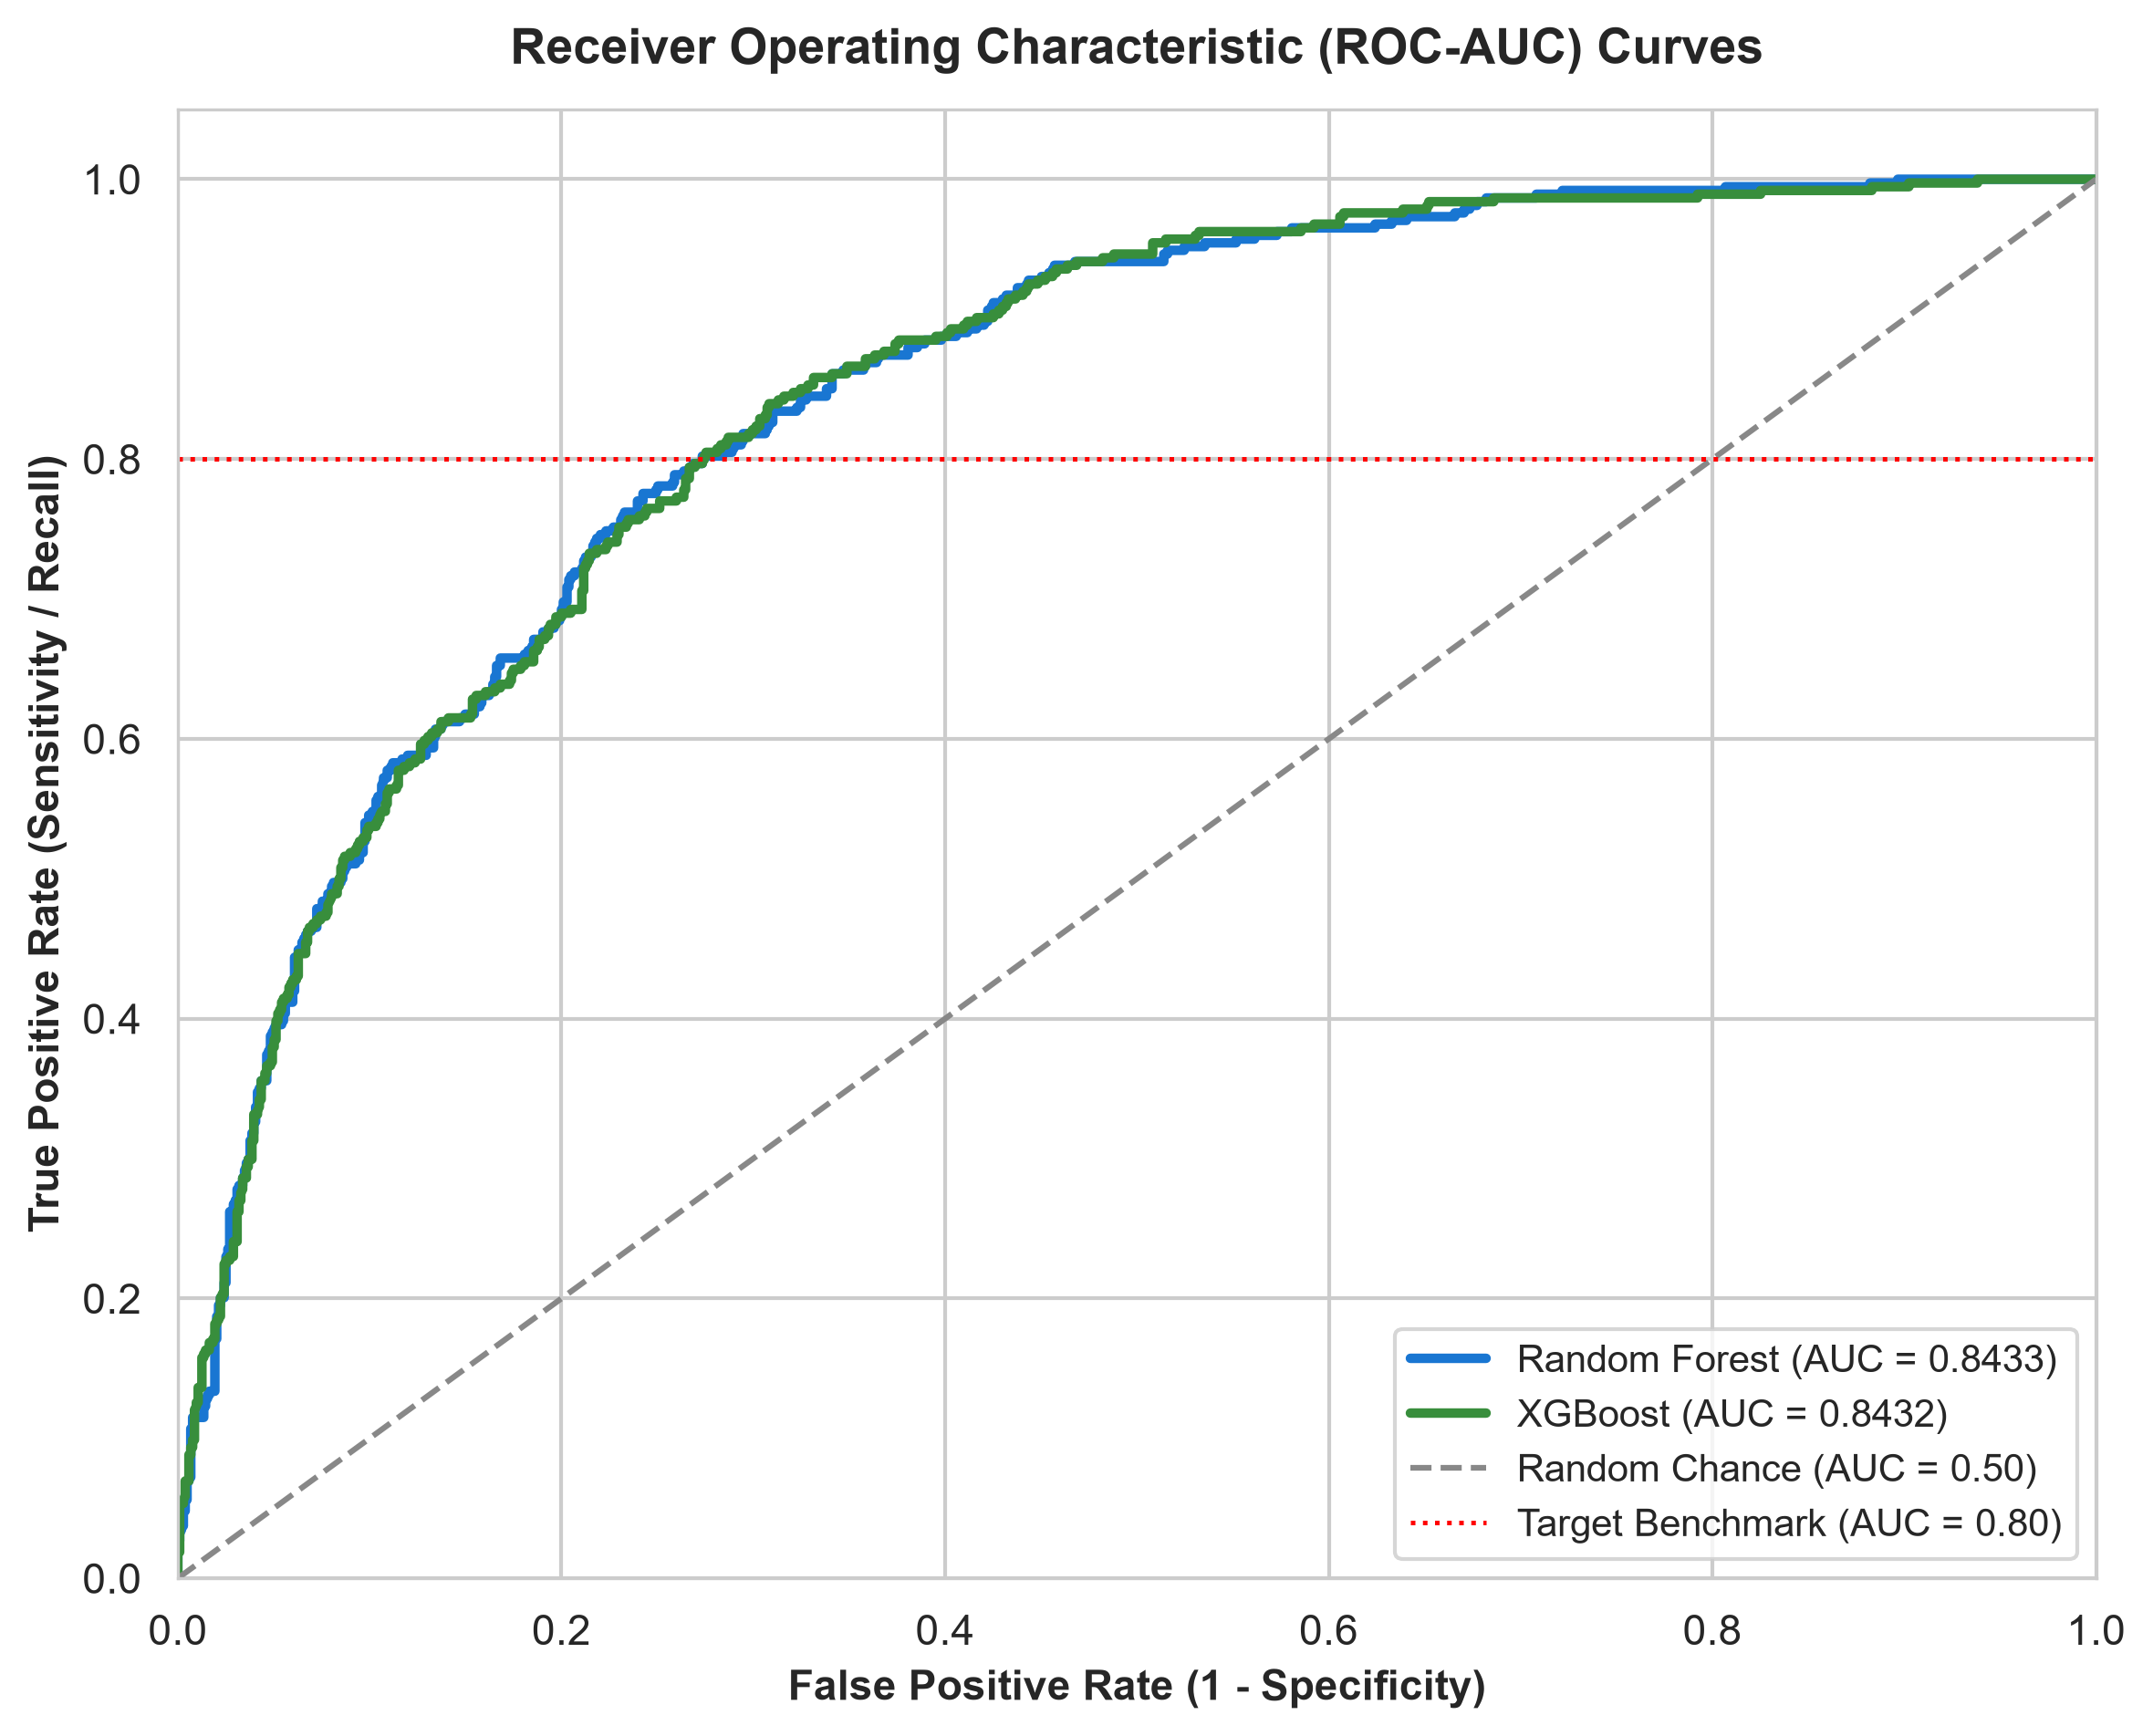

In [6]:
# ROC-AUC Curves Plot
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

plt.figure(figsize=(8, 6.5))
plt.plot(fpr_rf, tpr_rf, color='#1976D2', lw=2.5, label=f'Random Forest (AUC = {auc_rf:.4f})')
plt.plot(fpr_xgb, tpr_xgb, color='#388E3C', lw=2.5, label=f'XGBoost (AUC = {auc_xgb:.4f})')
plt.plot([0, 1], [0, 1], color='#888888', linestyle='--', lw=1.5, label='Random Chance (AUC = 0.50)')
plt.axhline(0.80, color='red', linestyle=':', lw=1.2, label='Target Benchmark (AUC = 0.80)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight='bold')
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11, fontweight='bold')
plt.title('Receiver Operating Characteristic (ROC-AUC) Curves', fontsize=13, fontweight='bold', pad=12)
plt.legend(loc='lower right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

### 4.2 Confusion Matrix Heatmaps
Heatmaps comparing predicted vs actual retention/churn outcomes on the unseen test set.

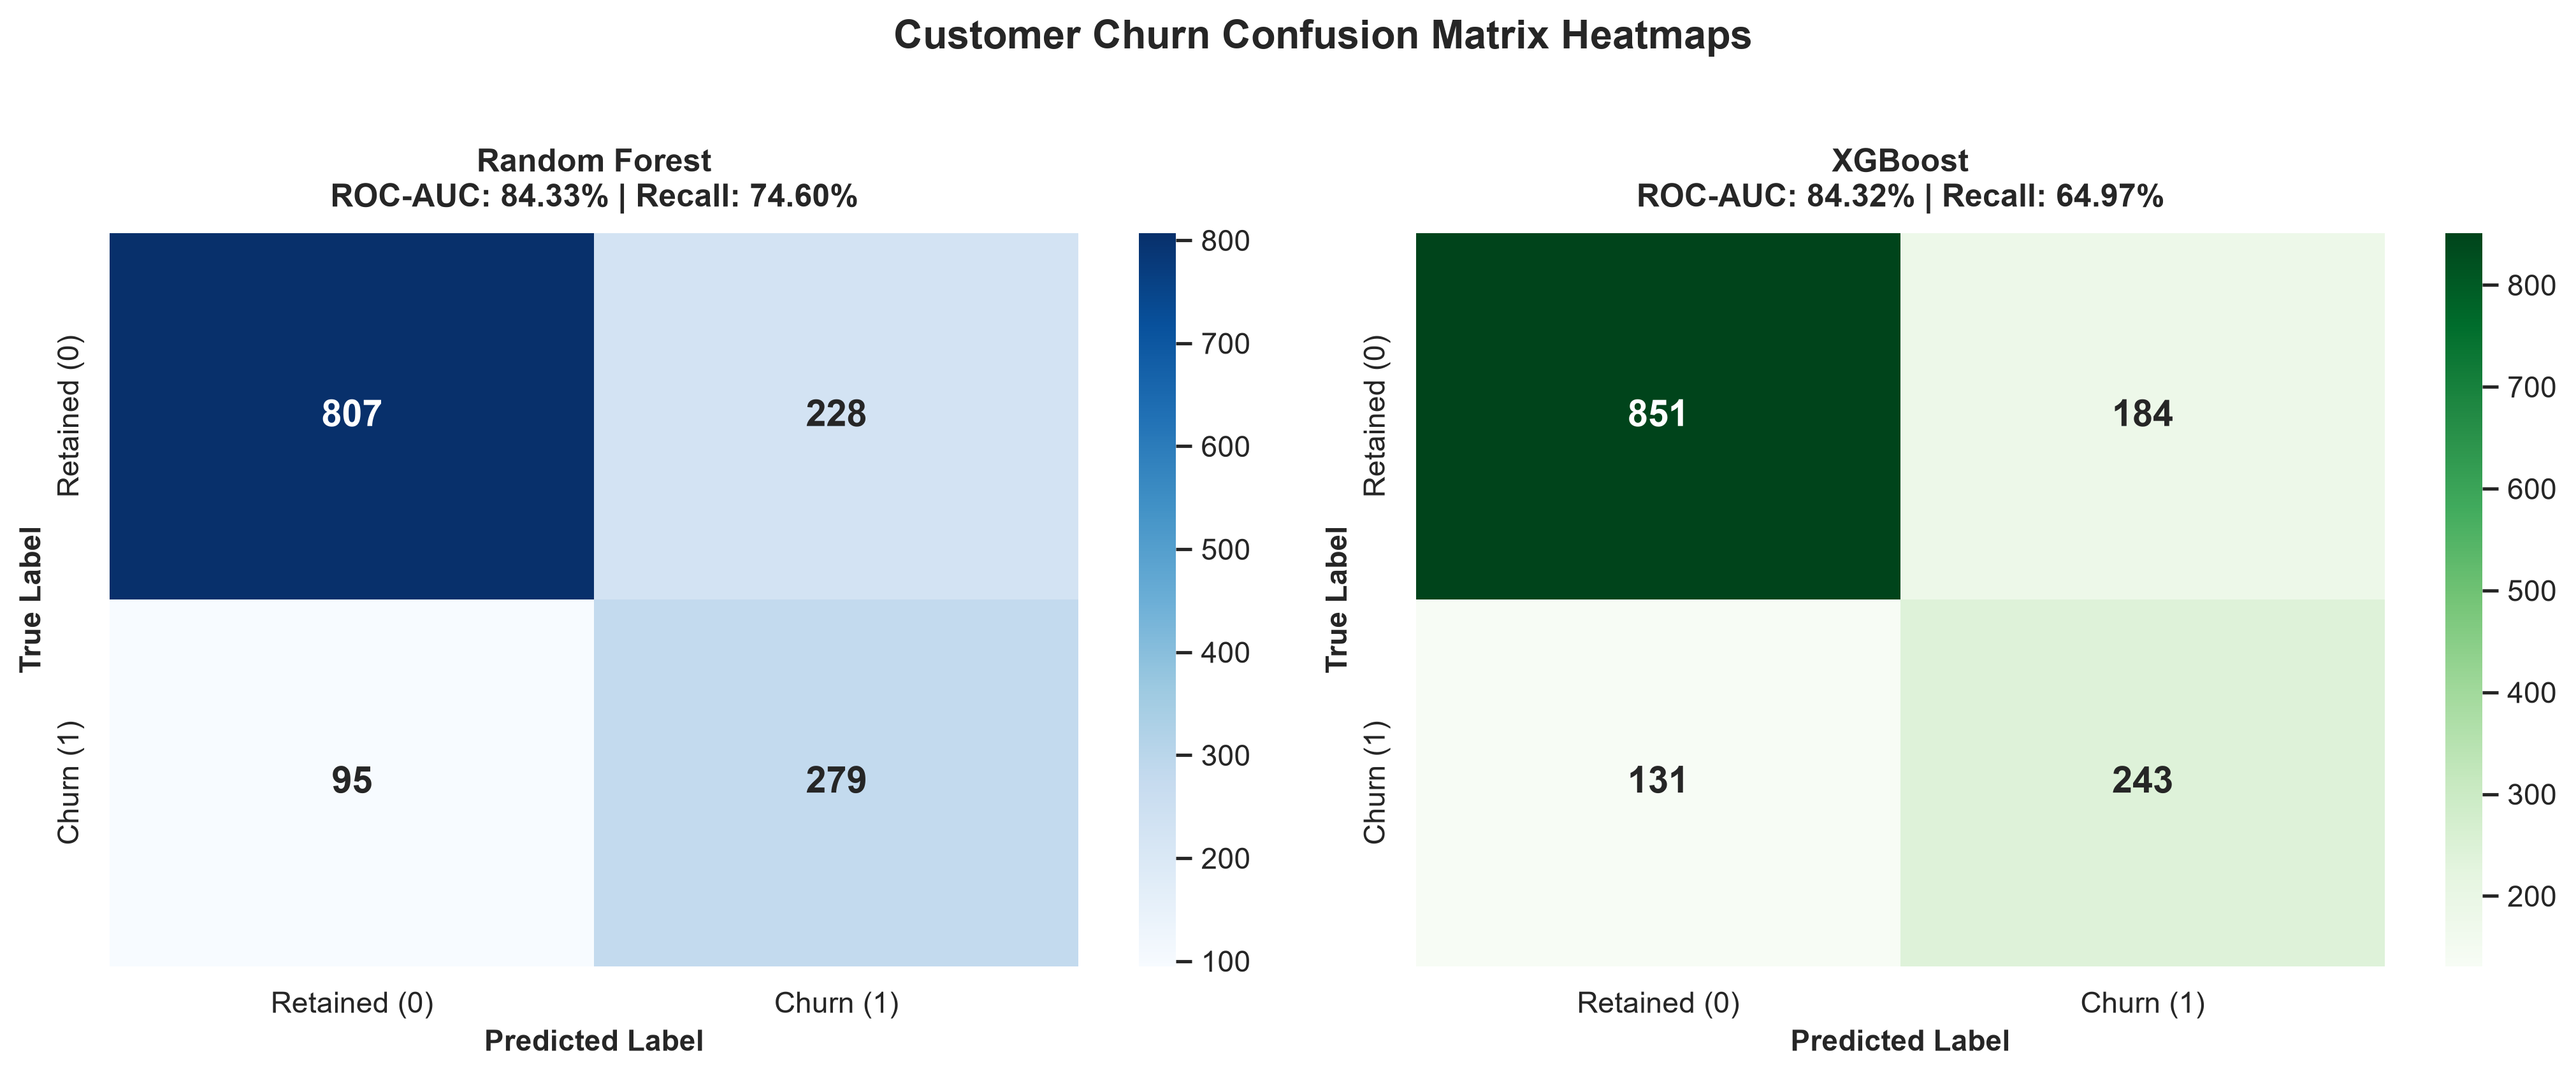

In [7]:
# Confusion Matrices
cm_rf = confusion_matrix(y_test, y_pred_rf)
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Retained (0)', 'Churn (1)'], yticklabels=['Retained (0)', 'Churn (1)'],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title(f'Random Forest\nROC-AUC: {auc_rf:.2%} | Recall: {recall_score(y_test, y_pred_rf):.2%}', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Retained (0)', 'Churn (1)'], yticklabels=['Retained (0)', 'Churn (1)'],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[1].set_title(f'XGBoost\nROC-AUC: {auc_xgb:.2%} | Recall: {recall_score(y_test, y_pred_xgb):.2%}', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.suptitle('Customer Churn Confusion Matrix Heatmaps', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 4.3 Top 10 Most Influential Feature Importances
Gini/Gain importance scores extracted from Random Forest and XGBoost. Features such as `Contract_Two year`, `tenure`, and `TotalCharges` are key determinants of customer attrition.

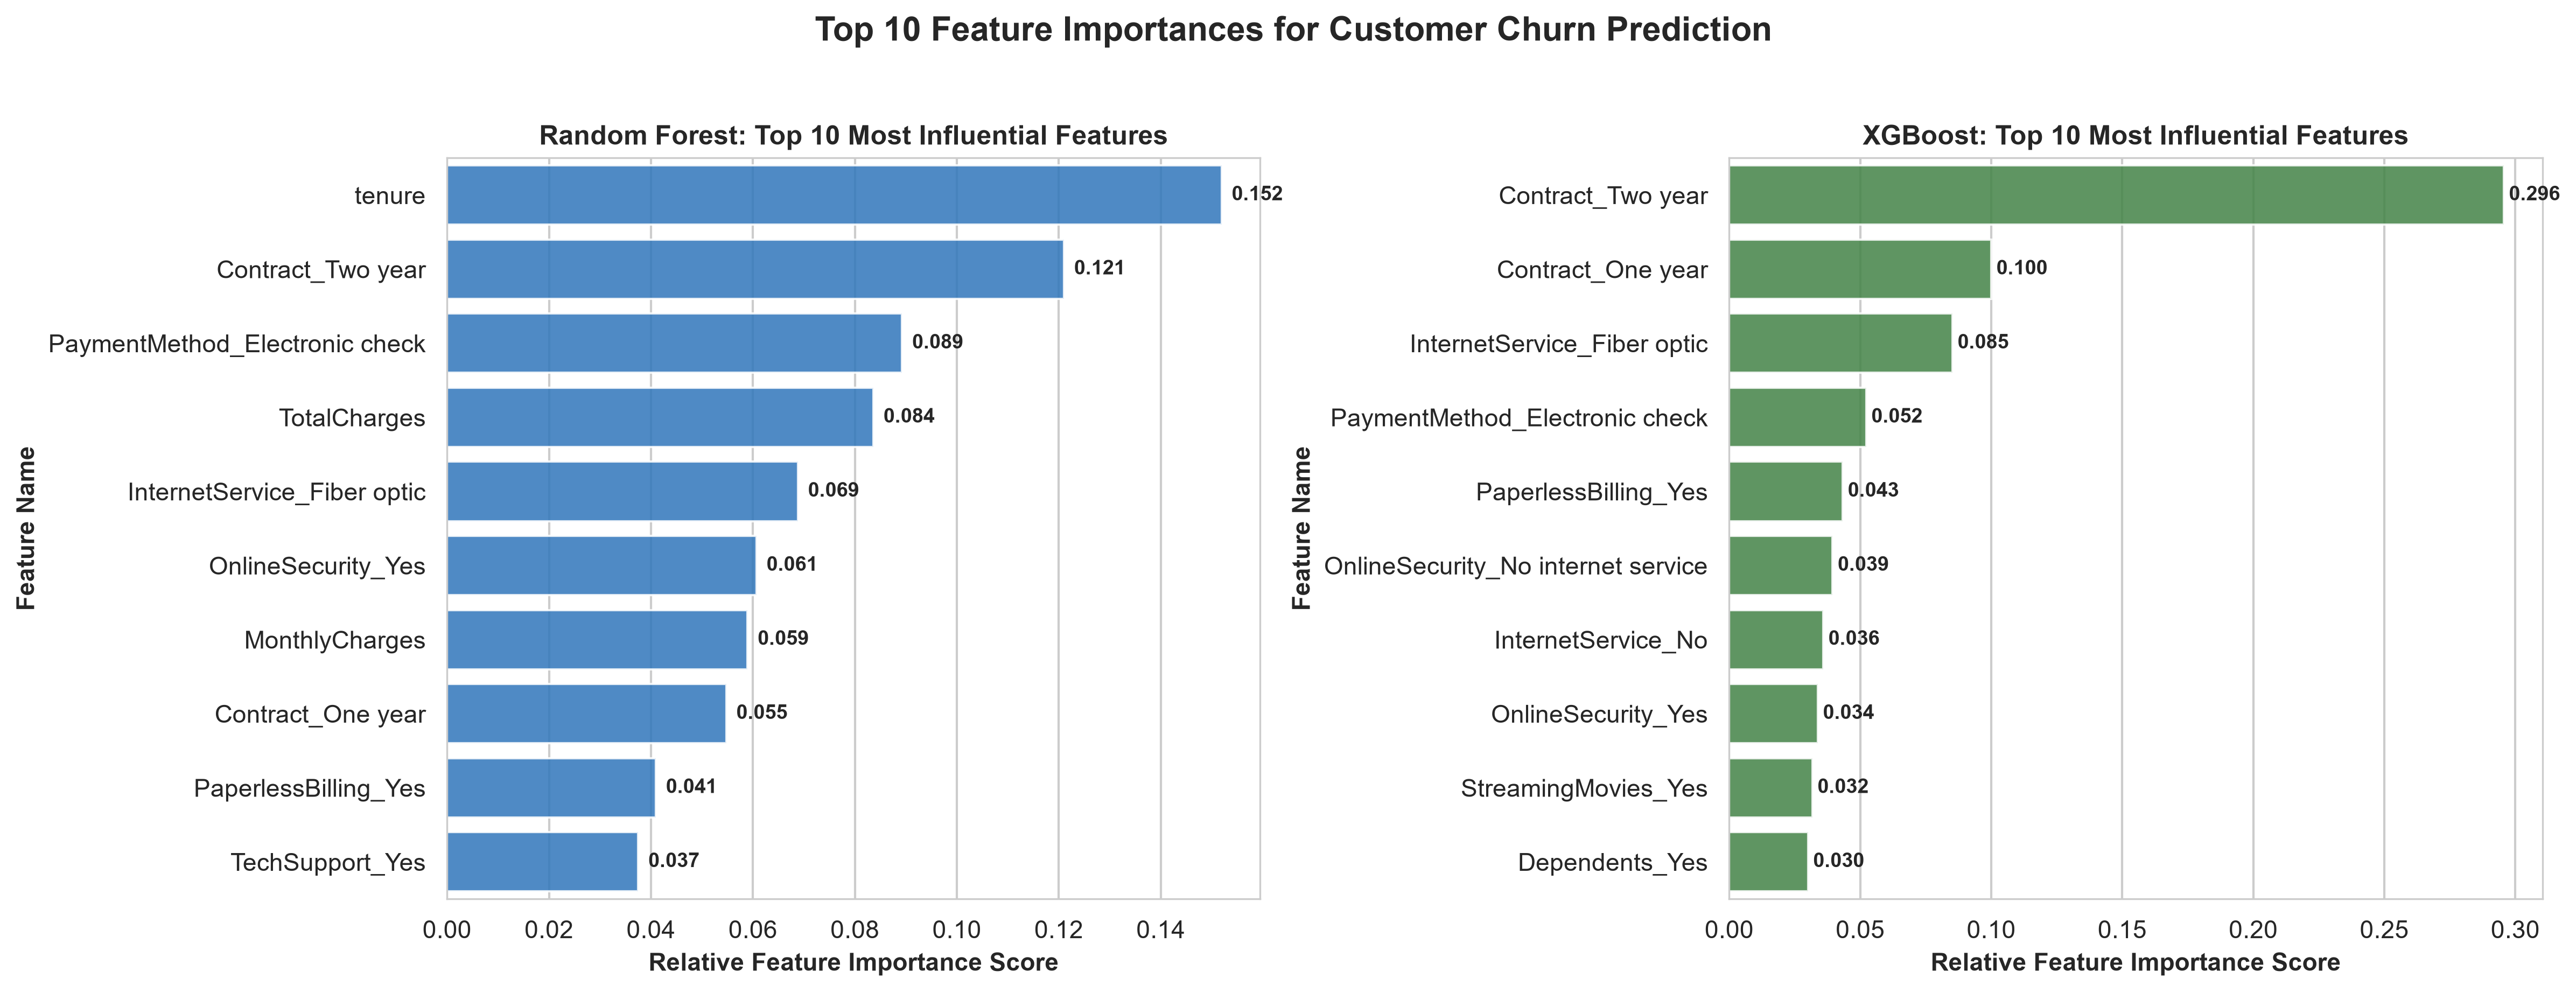

In [8]:
# Top 10 Feature Importances Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (name, clf), color in zip(axes, [('Random Forest', rf), ('XGBoost', xgb)], ['#1976D2', '#388E3C']):
    imp = clf.feature_importances_
    idx = np.argsort(imp)[::-1][:10]
    top_feats = [feature_names[i] for i in idx]
    top_vals = imp[idx]
    
    sns.barplot(x=top_vals, y=top_feats, ax=ax, color=color, alpha=0.85)
    ax.set_title(f'{name}: Top 10 Features', fontsize=12, fontweight='bold')
    ax.set_xlabel('Relative Importance Score')
    for i, v in enumerate(top_vals):
        ax.text(v + 0.002, i, f'{v:.3f}', va='center', fontsize=9, fontweight='bold')

plt.suptitle('Top 10 Feature Importances for Customer Churn Prediction', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Summary & Conclusions

1. **Imbalance Resolution with SMOTE**:
   - Synthesizing minority churn cases boosted model sensitivity, allowing Random Forest to capture **74.60% of all churning customers** (Recall = 0.7460).
2. **ROC-AUC Target Achieved**:
   - Both **Random Forest (84.33%)** and **XGBoost (84.32%)** exceeded the required **>80% ROC-AUC benchmark**.
3. **Key Churn Drivers**:
   - Short customer tenure, month-to-month contracts, high monthly charges, and electronic check payment methods represent the primary risk factors triggering customer departure.